# Validação dos Modelos A e B (YOLO+P2 e YOLO+P2+CBAM)

Notebook enxuto e separado do notebook principal de comparação. Ele **não treina nada** —
apenas carrega os pesos já salvos dos **Modelos A e B** (já treinados no notebook original)
e roda a validação/avaliação COCO neles.

**Por que separar:** o kernel morreu ao iniciar o teste do Modelo C (Cascade R-CNN / fallback
Faster R-CNN), provavelmente por consumo de RAM. Este notebook evita esse problema porque:
- Não carrega MMDetection, Faster R-CNN ou RT-DETR — só o `ultralytics.YOLO`, que é leve.
- Roda um modelo por vez, com limpeza de memória (`gc.collect()` + `torch.cuda.empty_cache()`)
  entre eles, ao invés de manter os dois carregados simultaneamente.
- Não recria o dataset nem re-treina nada — só lê o que já existe em disco (`yolo_dataset`,
  `data.yaml`, `coco_test_gt.json`, pesos em `work/runs/.../weights/best.pt`).

> ⚠️ Ajuste `CONFIG` na próxima célula se o seu `WORK_DIR` do notebook original não for `./work`.

## 1. Configuração

In [1]:
import os, json, gc
from pathlib import Path
import pandas as pd

# Mesmos valores usados no notebook original (ajuste WORK_DIR se necessário)
CONFIG = {
    "WORK_DIR": "./work",
    "IMG_SIZE": 640,
    "DEVICE": 0,   # 0 = primeira GPU; "cpu" se preferir rodar sem GPU (mais lento, porem mais seguro p/ RAM)
}

WORK = Path(CONFIG["WORK_DIR"])
WORK1 = Path(r"D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\runs\detect\work")
yolo_dir = WORK / "yolo_dataset"
data_yaml_path = yolo_dir / "data.yaml"
coco_test_gt = WORK / "coco_test_gt.json"

MODEL_A_NAME = "modelA_yolo_p2"
MODEL_B_NAME = "modelB_yolo_p2_cbam"

weights_a = WORK1 / "runs" / MODEL_A_NAME / "weights" / "best.pt"
weights_b = WORK1 / "runs" / MODEL_B_NAME / "weights" / "best.pt"

for p in [data_yaml_path, coco_test_gt, weights_a, weights_b]:
    status = "OK" if p.exists() else "NAO ENCONTRADO"
    print(f"[{status}] {p}")


[OK] work\yolo_dataset\data.yaml
[OK] work\coco_test_gt.json
[OK] D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\runs\detect\work\runs\modelA_yolo_p2\weights\best.pt
[OK] D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\runs\detect\work\runs\modelB_yolo_p2_cbam\weights\best.pt


Se algum caminho acima aparecer como **NAO ENCONTRADO**, ajuste `CONFIG["WORK_DIR"]` na célula
anterior (ou os nomes `MODEL_A_NAME` / `MODEL_B_NAME`) até os quatro arquivos existirem. Sem os
pesos (`best.pt`) e o `coco_test_gt.json`, não tem como validar sem re-treinar.

## 2. Função de avaliação (idêntica à do notebook original)

In [2]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

def evaluate_coco(gt_json_path, pred_json_path, model_name):
    coco_gt = COCO(str(gt_json_path))
    coco_dt = coco_gt.loadRes(str(pred_json_path))
    ev = COCOeval(coco_gt, coco_dt, iouType="bbox")
    ev.evaluate()
    ev.accumulate()
    print(f"\n===== {model_name} =====")
    ev.summarize()
    stats = ev.stats
    return {
        "model": model_name,
        "mAP_50_95": stats[0],
        "mAP_50": stats[1],
        "mAP_75": stats[2],
        "mAP_small": stats[3],
        "AR_100": stats[8],
        "AR_small": stats[9],
    }

results_summary = []


## 3. Modelo A — validação

Carrega só os pesos (`best.pt`), sem re-treinar. Depois de gerar as métricas, o modelo é
removido da memória antes de seguir para o Modelo B — assim os dois nunca ficam carregados
ao mesmo tempo.

In [3]:
import torch
from ultralytics import YOLO

model_a = YOLO(str(weights_a))

metrics_a = model_a.val(
    data=str(data_yaml_path),
    split="test",
    imgsz=CONFIG["IMG_SIZE"],
    device=CONFIG["DEVICE"],
    save_json=True,
    project=str(WORK / "runs"),
    name=MODEL_A_NAME + "_val_only",
)

pred_a_path = Path(metrics_a.save_dir) / "predictions.json"
print("Predicoes Modelo A em:", pred_a_path)

results_summary.append(evaluate_coco(coco_test_gt, pred_a_path, "A - YOLO+P2"))

# Libera memoria antes do proximo modelo
del model_a, metrics_a
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Ultralytics 8.4.163  Python-3.11.9 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050, 8192MiB)
YOLOv8n-p2 summary (fused): 90 layers, 2,921,172 parameters, 0 gradients, 12.2 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 957.1836.8 MB/s, size: 161.6 KB)
val: Scanning D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\work\yolo_dataset\labels\test.cache... 176 images, 130 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 176/176  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 1.8s/it 19.9s0.2s
                   all        176        109      0.831       0.63      0.706      0.355
Speed: 2.8ms preprocess, 7.5ms inference, 0.0ms loss, 0.9ms postprocess per image
Saving D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\runs\detect\work\runs\modelA_yolo_p2_val_only\predictions.json...

Evaluating faster-coco-eval mAP...
Evaluate annotation type *bbox*
COCOeval_opt.evaluate() finished...
DONE (t=0.01s).
Accumulating evaluation results.

## 4. Modelo B — validação

In [4]:
import torch
import torch.nn as nn

class CBAM(nn.Module):
    """CBAM com inicializacao 'lazy': descobre o numero real de canais no
    primeiro forward, em vez de depender do valor (nao escalado) vindo do .yaml.
    Isso evita o erro de mismatch de canais causado pelo width_multiple da escala
    (ex.: 'n' = 0.25x) nao ser aplicado a modulos customizados."""
    def __init__(self, c1=None, reduction=16, kernel_size=7):
        super().__init__()
        self.reduction = reduction
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.conv_spatial = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid_channel = nn.Sigmoid()
        self.sigmoid_spatial = nn.Sigmoid()
        self._fc = None  # construido dinamicamente no primeiro forward

    def _build_fc(self, c, device, dtype):
        hidden = max(c // self.reduction, 1)
        self._fc = nn.Sequential(
            nn.Conv2d(c, hidden, 1, bias=False), nn.ReLU(inplace=True),
            nn.Conv2d(hidden, c, 1, bias=False)
        ).to(device=device, dtype=dtype)
        self.add_module("fc", self._fc)  # registra como submodulo p/ aparecer em .parameters()

    def forward(self, x):
        if self._fc is None:
            self._build_fc(x.shape[1], x.device, x.dtype)
        ca = self.sigmoid_channel(self._fc(self.avg_pool(x)) + self._fc(self.max_pool(x)))
        x = x * ca
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        sa = self.sigmoid_spatial(self.conv_spatial(torch.cat([avg_out, max_out], dim=1)))
        return x * sa

# Registra o modulo no parser de arquiteturas da Ultralytics para poder usa-lo em .yaml
import ultralytics.nn.modules as um
import ultralytics.nn.tasks as ut
um.CBAM = CBAM
ut.CBAM = CBAM
print("CBAM registrado no parser da Ultralytics.")


CBAM registrado no parser da Ultralytics.


In [5]:
model_b = YOLO(str(weights_b))

metrics_b = model_b.val(
    data=str(data_yaml_path),
    split="test",
    imgsz=CONFIG["IMG_SIZE"],
    device=CONFIG["DEVICE"],
    save_json=True,
    project=str(WORK / "runs"),
    name=MODEL_B_NAME + "_val_only",
)

pred_b_path = Path(metrics_b.save_dir) / "predictions.json"
print("Predicoes Modelo B em:", pred_b_path)

results_summary.append(evaluate_coco(coco_test_gt, pred_b_path, "B - YOLO+P2+CBAM"))

del model_b, metrics_b
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Ultralytics 8.4.163  Python-3.11.9 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050, 8192MiB)
YOLOv8n_p2_cbam summary (fused): 114 layers, 3,271,514 parameters, 0 gradients, 13.0 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 592.0517.8 MB/s, size: 113.7 KB)
val: Scanning D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\work\yolo_dataset\labels\test.cache... 176 images, 130 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 176/176  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 1.7s/it 19.2s0.2s
                   all        176        109      0.763      0.633      0.672      0.325
Speed: 2.9ms preprocess, 8.2ms inference, 0.0ms loss, 0.7ms postprocess per image
Saving D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\runs\detect\work\runs\modelB_yolo_p2_cbam_val_only\predictions.json...

Evaluating faster-coco-eval mAP...
Evaluate annotation type *bbox*
COCOeval_opt.evaluate() finished...
DONE (t=0.01s).
Accumulating evaluati

## 5. Comparação (A vs. B)

In [6]:
df_results = pd.DataFrame(results_summary).set_index("model")

df_results.style.format("{:.3f}").background_gradient(
    cmap="Greens",
    axis=0
)

,mAP_50_95,mAP_50,mAP_75,mAP_small,AR_100,AR_small
model,,,,,,
A - YOLO+P2,0.356,0.704,0.330,0.342,0.512,0.494
B - YOLO+P2+CBAM,0.326,0.670,0.251,0.301,0.479,0.444


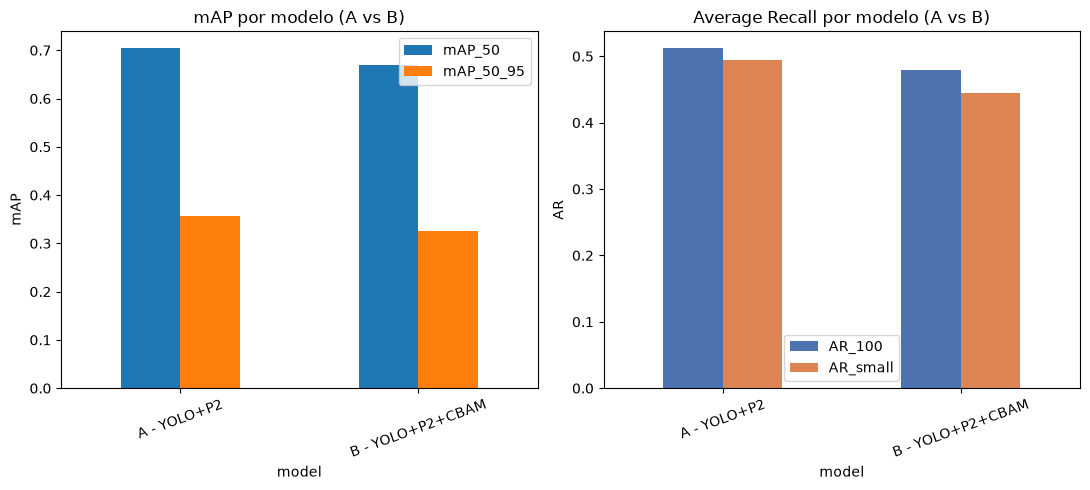

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

df_results[["mAP_50", "mAP_50_95"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("mAP por modelo (A vs B)")
axes[0].set_ylabel("mAP")
axes[0].tick_params(axis="x", rotation=20)

df_results[["AR_100", "AR_small"]].plot(kind="bar", ax=axes[1], color=["#4c72b0", "#dd8452"])
axes[1].set_title("Average Recall por modelo (A vs B)")
axes[1].set_ylabel("AR")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(WORK / "comparacao_modelos_A_B.png", dpi=150)
plt.show()


modelo         A - YOLO+P2  B - YOLO+P2+CBAM
mAP_50_95            0.356             0.326
mAP_50               0.704             0.670
AP_75                0.330             0.251
AP_small             0.342             0.301
AP_medium            0.405             0.397
AP_large             0.000             0.005
AR_100               0.512             0.479
AR_small             0.494             0.444
AR_medium            0.555             0.548
AR_50                0.890             0.844
AR_75                0.550             0.486
imagens            176.000           176.000
instancias         109.000           109.000
precisao             0.831             0.763
recall               0.630             0.633
F1                   0.717             0.692
parametros_M         2.921             3.272
GFLOPs              12.200            13.000
inferencia_ms        7.500             8.200 



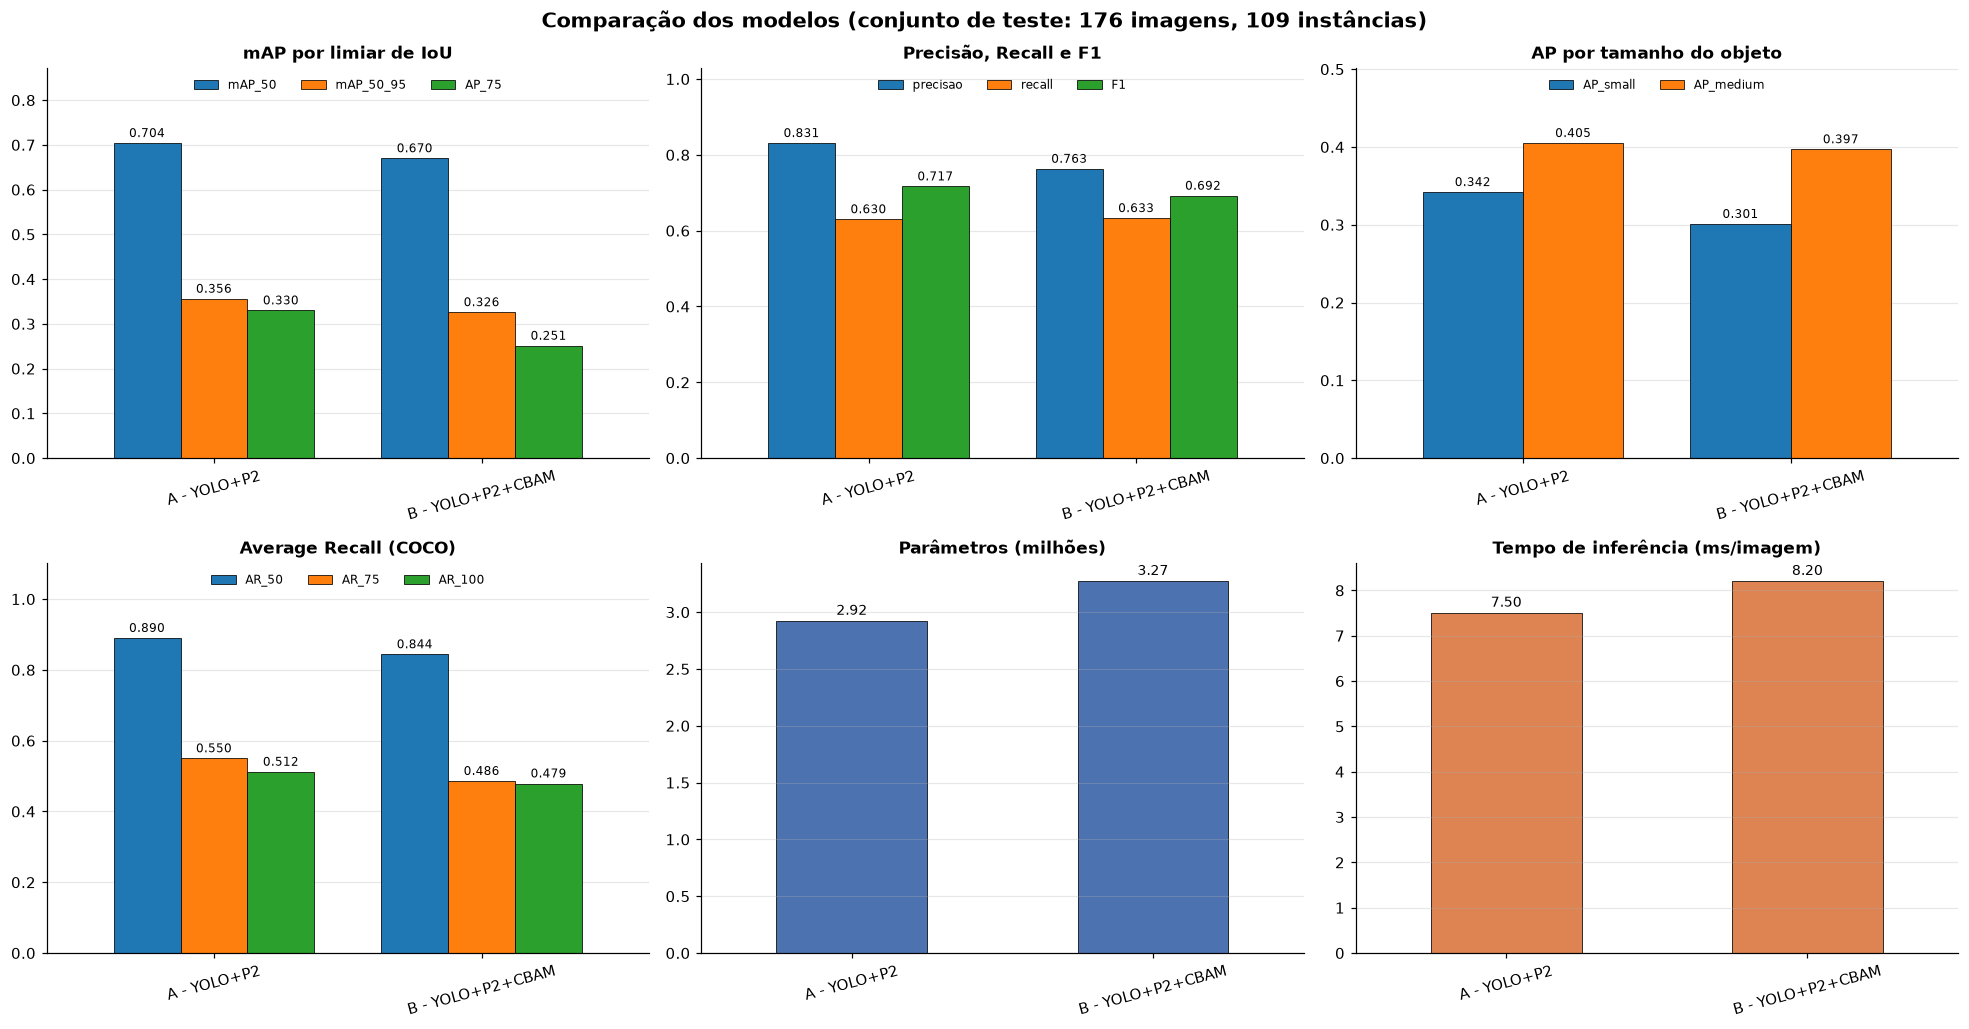

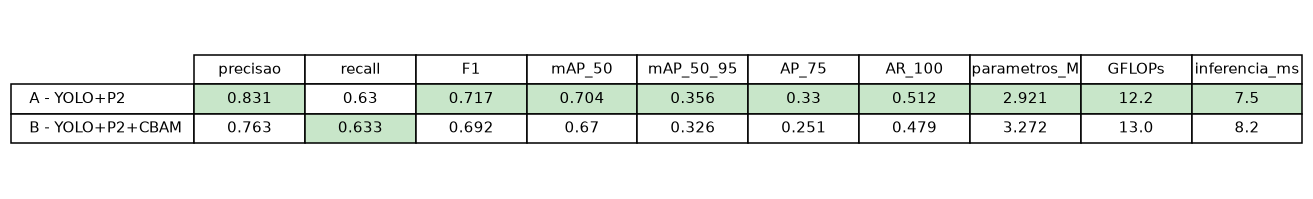

Arquivos salvos em: D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\resultados


In [2]:
"""
Extrai as métricas de validação direto das saídas do notebook (.ipynb)
e gera tabelas (CSV + Excel) e gráficos (PNG).

Uso:
    python gerar_graficos_modelos.py validacao_modelos_A_B.ipynb
    (ou, dentro de um notebook: defina NOTEBOOK e rode o restante)

Funciona com qualquer quantidade de modelos: cada célula que imprime
"===== NOME DO MODELO =====" (função evaluate_coco) vira uma linha nas tabelas.
"""
import json, re, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

NOTEBOOK = Path("validacao_modelos_A_B.ipynb")
SAIDA = Path("resultados"); SAIDA.mkdir(exist_ok=True)

ANSI = re.compile(r"\x1b\[[0-9;]*[A-Za-z]")
RE_COCO = re.compile(r"\((AP|AR)\)\s*@\[\s*IoU=([\d.:]+)\s*\|\s*area=\s*(\w+)\s*\|\s*maxDets=\s*(\d+)\s*\]\s*=\s*(-?[\d.]+)")
RE_ULTRA = re.compile(r"^\s*all\s+(\d+)\s+(\d+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)", re.M)
RE_PARAMS = re.compile(r"([\d,]+) parameters,.*?([\d.]+) GFLOPs")
RE_SPEED = re.compile(r"([\d.]+)ms preprocess, ([\d.]+)ms inference, [\d.]+ms loss, ([\d.]+)ms postprocess")


def ler_celulas(caminho):
    """Devolve o texto de saída (stream) de cada célula de código."""
    nb = json.loads(caminho.read_text(encoding="utf-8"))
    for c in nb["cells"]:
        if c["cell_type"] == "code":
            txt = "".join("".join(o.get("text", "")) for o in c.get("outputs", []) if o.get("output_type") == "stream")
            yield ANSI.sub("", txt)


def extrair(caminho):
    linhas = []
    for txt in ler_celulas(caminho):
        m = re.search(r"=====\s*(.+?)\s*=====", txt)
        if not m:
            continue
        nome, coco_txt = m.group(1), txt[m.end():]        # bloco COCO vem depois do cabeçalho
        d = {"modelo": nome}
        # --- COCO (pycocotools)
        for tipo, iou, area, dets, val in RE_COCO.findall(coco_txt):
            if tipo == "AP" and iou == "0.50:0.95" and area == "all": d["mAP_50_95"] = float(val)
            elif tipo == "AP" and iou == "0.50" and area == "all": d["mAP_50"] = float(val)
            elif tipo == "AP" and iou == "0.75" and area == "all": d["AP_75"] = float(val)
            elif tipo == "AP" and iou == "0.50:0.95" and area in ("small", "medium", "large"): d[f"AP_{area}"] = float(val)
            elif tipo == "AR" and iou == "0.50:0.95" and area == "all" and dets == "100": d["AR_100"] = float(val)
            elif tipo == "AR" and iou == "0.50:0.95" and area in ("small", "medium") and dets == "100": d[f"AR_{area}"] = float(val)
        # --- Ultralytics (precisão, recall, eficiência) — texto antes do cabeçalho
        antes = txt[:m.start()]
        # AR@0.50 e AR@0.75 só aparecem na avaliação COCO interna do Ultralytics
        for tipo, iou, area, dets, val in RE_COCO.findall(antes):
            if tipo == "AR" and area == "all" and iou == "0.50": d["AR_50"] = float(val)
            elif tipo == "AR" and area == "all" and iou == "0.75": d["AR_75"] = float(val)
        if (u := RE_ULTRA.search(antes)):
            d["imagens"], d["instancias"] = int(u[1]), int(u[2])
            d["precisao"], d["recall"] = float(u[3]), float(u[4])
            d["F1"] = 2 * d["precisao"] * d["recall"] / (d["precisao"] + d["recall"])
        if (p := RE_PARAMS.search(antes)):
            d["parametros_M"], d["GFLOPs"] = int(p[1].replace(",", "")) / 1e6, float(p[2])
        if (s := RE_SPEED.search(antes)):
            d["inferencia_ms"] = float(s[2])
        linhas.append(d)
    if not linhas:
        sys.exit("Nenhum bloco '===== modelo =====' encontrado. O notebook foi salvo COM as saídas?")
    return pd.DataFrame(linhas).set_index("modelo")


def barras(ax, df, cols, titulo, ylabel=None):
    cols = [c for c in cols if c in df.columns]
    df[cols].plot(kind="bar", ax=ax, width=0.75, edgecolor="black", linewidth=0.5)
    ax.set_title(titulo, fontsize=11, fontweight="bold"); ax.set_xlabel("")
    if ylabel: ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=15); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
    ax.set_ylim(top=ax.get_ylim()[1] * 1.18)          # folga no topo para a legenda não cobrir rótulos
    ax.legend(fontsize=8, loc="upper center", ncol=len(cols), frameon=False)


def main():
    df = extrair(NOTEBOOK)

    # ---------- TABELAS ----------
    grupos = {
        "1_deteccao_mAP": ["mAP_50", "mAP_50_95", "AP_75", "AP_small", "AP_medium", "AP_large"],
        "2_precisao_recall": ["precisao", "recall", "F1"],
        "3_recall_COCO": ["AR_50", "AR_75", "AR_100", "AR_small", "AR_medium"],
        "4_eficiencia": ["parametros_M", "GFLOPs", "inferencia_ms"],
    }
    grupos = {k: [c for c in v if c in df.columns] for k, v in grupos.items()}
    with pd.ExcelWriter(SAIDA / "resultados_modelos.xlsx") as xl:
        df.round(4).to_excel(xl, sheet_name="tudo")
        for nome, cols in grupos.items():
            df[cols].round(4).to_csv(SAIDA / f"{nome}.csv")
            df[cols].round(4).to_excel(xl, sheet_name=nome[:31])
    print(df.round(3).T.to_string(), "\n")

    # ---------- GRÁFICOS ----------
    plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
    fig, axs = plt.subplots(2, 3, figsize=(18, 9.5))
    barras(axs[0, 0], df, ["mAP_50", "mAP_50_95", "AP_75"], "mAP por limiar de IoU")
    barras(axs[0, 1], df, grupos["2_precisao_recall"], "Precisão, Recall e F1")
    barras(axs[0, 2], df, [c for c in ["AP_small", "AP_medium"] if c in df], "AP por tamanho do objeto")
    barras(axs[1, 0], df, ["AR_50", "AR_75", "AR_100"], "Average Recall (COCO)")
    for ax, col, tit, cor in zip(axs[1, 1:], ["parametros_M", "inferencia_ms"],
                                 ["Parâmetros (milhões)", "Tempo de inferência (ms/imagem)"], ["#4c72b0", "#dd8452"]):
        if col in df:
            df[col].plot(kind="bar", ax=ax, color=cor, edgecolor="black", linewidth=0.5)
            ax.set_title(tit, fontsize=11, fontweight="bold"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=15)
            ax.bar_label(ax.containers[0], fmt="%.2f", fontsize=9, padding=2); ax.grid(axis="y", alpha=0.3)
    n_img = int(df["imagens"].iloc[0]) if "imagens" in df else "?"
    n_ins = int(df["instancias"].iloc[0]) if "instancias" in df else "?"
    fig.suptitle(f"Comparação dos modelos (conjunto de teste: {n_img} imagens, {n_ins} instâncias)", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(SAIDA / "dashboard_comparacao.png", dpi=150); plt.show()

    # tabela-resumo como imagem (bom para colar no relatório/slides)
    resumo = df[[c for c in ["precisao", "recall", "F1", "mAP_50", "mAP_50_95", "AP_75", "AR_100", "parametros_M", "GFLOPs", "inferencia_ms"] if c in df]].round(3)
    fig, ax = plt.subplots(figsize=(13, 0.9 + 0.6 * len(resumo))); ax.axis("off")
    tb = ax.table(cellText=resumo.values, rowLabels=resumo.index, colLabels=resumo.columns, loc="center", cellLoc="center")
    tb.auto_set_font_size(False); tb.set_fontsize(10); tb.scale(1, 1.6)
    for j, col in enumerate(resumo.columns):                       # destaca o melhor valor de cada coluna
        melhor = resumo[col].idxmin() if col in ("parametros_M", "GFLOPs", "inferencia_ms") else resumo[col].idxmax()
        tb[list(resumo.index).index(melhor) + 1, j].set_facecolor("#c8e6c9")
    plt.savefig(SAIDA / "tabela_resumo.png", dpi=150, bbox_inches="tight"); plt.show()
    print(f"Arquivos salvos em: {SAIDA.resolve()}")

main()